In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.preprocessing import normalize

BASE = Path.cwd().parent
DATA = BASE / "Datasets" / "processed" / "dataset.csv"
RESULTS = BASE / "Results"
RESULTS.mkdir(exist_ok=True)

df = pd.read_csv(DATA).fillna({"title": "", "abstract": "", "ref_dois": ""})

MULTI_LABEL = True
if not MULTI_LABEL:
    df = df[df.n_labels == 1].reset_index(drop=True)

label_cols = [c for c in df.columns if c.startswith("lbl_")]
names = [c[4:] for c in label_cols]
Y = df[label_cols].values


dev_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=42, shuffle=True)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.25, random_state=42, shuffle=True)

print(f"train {len(train_idx)} | validation {len(val_idx)} | test {len(test_idx)}")

train 4914 | validation 1639 | test 1639


In [2]:


def truncate(text, fraction):
    
    words = str(text).split()
    return " ".join(words[:max(1, int(len(words) * fraction))]) if words else ""


CONDITIONS = {
    "full":        (df.title + " " + df.abstract).values,
    "abstract_75": (df.title + " " + df.abstract.apply(lambda t: truncate(t, .75))).values,
    "abstract_50": (df.title + " " + df.abstract.apply(lambda t: truncate(t, .50))).values,
    "abstract_25": (df.title + " " + df.abstract.apply(lambda t: truncate(t, .25))).values,
    "title_only":  df.title.values,
    "no_text":     np.array([""] * len(df)),
}

print(f"{'condition':<14}{'avg words':>12}")
for name, txt in CONDITIONS.items():
    print(f"{name:<14}{np.mean([len(str(t).split()) for t in txt]):>12.1f}")

condition        avg words
full                 203.9
abstract_75          155.6
abstract_50          107.7
abstract_25           59.6
title_only            12.0
no_text                0.0


In [3]:

vocabulary, row_idx, col_idx = {}, [], []
for i, refs in enumerate(df.ref_dois):
    for r in (x for x in refs.split("|") if x):
        j = vocabulary.setdefault(r, len(vocabulary))
        row_idx.append(i)
        col_idx.append(j)

X_cite = normalize(csr_matrix((np.ones(len(row_idx)), (row_idx, col_idx)),
                              shape=(len(df), len(vocabulary))))


def text_scores(txt, fit_idx, score_idx, C):
   
    if not any(str(t).strip() for t in txt[fit_idx]):
        return np.full((len(score_idx), Y.shape[1]), -1.0)

    vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2,
                          sublinear_tf=True, stop_words="english")
    X_fit = vec.fit_transform(txt[fit_idx])
    X_score = vec.transform(txt[score_idx])

    model = OneVsRestClassifier(LinearSVC(C=C, max_iter=3000), n_jobs=-1)
    model.fit(X_fit, Y[fit_idx])
    return model.decision_function(X_score)


def citation_scores(fit_idx, score_idx, k):
    
    S = (X_cite[score_idx] @ X_cite[fit_idx].T).toarray()
    kk = min(k, S.shape[1] - 1)
    nn = np.argpartition(-S, kk, axis=1)[:, :kk]
    out = np.zeros((len(score_idx), Y.shape[1]))
    for i in range(len(score_idx)):
        w = S[i, nn[i]]
        if w.sum() > 0:
            out[i] = (Y[fit_idx][nn[i]] * w[:, None]).sum(0) / w.sum()
    return out


def to_labels(scores, threshold):
    pred = (scores >= threshold).astype(int)
    empty = pred.sum(1) == 0
    pred[empty, scores[empty].argmax(1)] = 1
    return pred


def evaluate(y_true, pred):
    return (f1_score(y_true, pred, average="micro", zero_division=0),
            f1_score(y_true, pred, average="macro", zero_division=0))


def zscale(a):
    return (a - a.mean()) / (a.std() + 1e-9)


print("helpers defined")

helpers defined


In [4]:


print("text model — choosing C:")
best_C, best = None, -1
for C in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    s = text_scores(CONDITIONS["full"], train_idx, val_idx, C)
    micro = evaluate(Y[val_idx], to_labels(s, 0.0))[0]
    print(f"   C={C:<4} val micro-F1 {micro:.4f}")
    if micro > best:
        best, best_C = micro, C
print(f"   chosen C={best_C}\n")

print("citation model — choosing k and threshold:")
best_k, best_cthr, best = None, None, -1
for k in [5, 10, 20, 30, 50]:
    s = citation_scores(train_idx, val_idx, k)
    for thr in [0.20, 0.25, 0.30, 0.35, 0.40]:
        micro = evaluate(Y[val_idx], to_labels(s, thr))[0]
        if micro > best:
            best, best_k, best_cthr = micro, k, thr
print(f"   chosen k={best_k}, threshold={best_cthr} (val micro-F1 {best:.4f})")

text model — choosing C:
   C=0.1  val micro-F1 0.7329
   C=0.5  val micro-F1 0.7567
   C=1.0  val micro-F1 0.7587
   C=2.0  val micro-F1 0.7596
   C=5.0  val micro-F1 0.7551
   C=10.0 val micro-F1 0.7546
   chosen C=2.0

citation model — choosing k and threshold:
   chosen k=20, threshold=0.35 (val micro-F1 0.7605)


In [5]:


cite_val = citation_scores(train_idx, val_idx, best_k)
hybrid_settings = {}

print(f"{'condition':<14}{'w':>6}{'thr':>7}{'val micro-F1':>14}")
for cond, txt in CONDITIONS.items():
    text_val = text_scores(txt, train_idx, val_idx, best_C)
    bw, bt, bs = 0.5, 0.0, -1
    for w in [0.0, 0.2, 0.35, 0.5, 0.65, 0.8, 1.0]:
        combined = (1 - w) * zscale(text_val) + w * zscale(cite_val)
        for thr in [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]:
            micro = evaluate(Y[val_idx], to_labels(combined, thr))[0]
            if micro > bs:
                bs, bw, bt = micro, w, thr
    hybrid_settings[cond] = (bw, bt)
    print(f"{cond:<14}{bw:>6}{bt:>7}{bs:>14.4f}")

condition          w    thr  val micro-F1
full            0.35    1.0        0.7900
abstract_75     0.35    1.0        0.7853
abstract_50      0.5    1.0        0.7828
abstract_25      0.5    1.0        0.7810
title_only       0.5    1.0        0.7721
no_text          1.0   0.75        0.7621


In [6]:


fit_idx = np.concatenate([train_idx, val_idx])
cite_test = citation_scores(fit_idx, test_idx, best_k)
cite_micro, cite_macro = evaluate(Y[test_idx], to_labels(cite_test, best_cthr))

rows = []
for cond, txt in CONDITIONS.items():
    text_test = text_scores(txt, fit_idx, test_idx, best_C)
    t_mi, t_ma = evaluate(Y[test_idx], to_labels(text_test, 0.0))

    w, thr = hybrid_settings[cond]
    combined = (1 - w) * zscale(text_test) + w * zscale(cite_test)
    h_mi, h_ma = evaluate(Y[test_idx], to_labels(combined, thr))

    rows.append({"condition": cond,
                 "text_micro": round(t_mi, 3), "text_macro": round(t_ma, 3),
                 "cite_micro": round(cite_micro, 3), "cite_macro": round(cite_macro, 3),
                 "hybrid_micro": round(h_mi, 3), "hybrid_macro": round(h_ma, 3),
                 "w": w, "thr": thr})

results = pd.DataFrame(rows)
print(results[["condition", "text_micro", "cite_micro", "hybrid_micro"]].to_string(index=False))

results.to_csv(RESULTS / "ablation_results.csv", index=False)
print(f"\nsaved to {RESULTS / 'ablation_results.csv'}")

  condition  text_micro  cite_micro  hybrid_micro
       full       0.750       0.752         0.779
abstract_75       0.740       0.752         0.775
abstract_50       0.731       0.752         0.775
abstract_25       0.714       0.752         0.767
 title_only       0.667       0.752         0.759
    no_text       0.103       0.752         0.751

saved to /Users/kalai/Documents/Dissertation/Results/ablation_results.csv


In [7]:
print("Where does citation overtake text?\n")
print(f"{'condition':<14}{'text':>8}{'citation':>10}{'difference':>12}{'winner':>10}")
for _, r in results.iterrows():
    diff = r.text_micro - r.cite_micro
    winner = "text" if diff > 0 else "CITATION"
    print(f"{r.condition:<14}{r.text_micro:>8.3f}{r.cite_micro:>10.3f}"
          f"{diff:>+12.3f}{winner:>10}")

print(f"\nThe citation model is flat at {cite_micro:.3f} in every condition,")
print("because it never uses text. The crossover is where the falling text")
print("line meets that flat line — and that is the answer to the research question.")

Where does citation overtake text?

condition         text  citation  difference    winner
full             0.750     0.752      -0.002  CITATION
abstract_75      0.740     0.752      -0.012  CITATION
abstract_50      0.731     0.752      -0.021  CITATION
abstract_25      0.714     0.752      -0.038  CITATION
title_only       0.667     0.752      -0.085  CITATION
no_text          0.103     0.752      -0.649  CITATION

The citation model is flat at 0.752 in every condition,
because it never uses text. The crossover is where the falling text
line meets that flat line — and that is the answer to the research question.


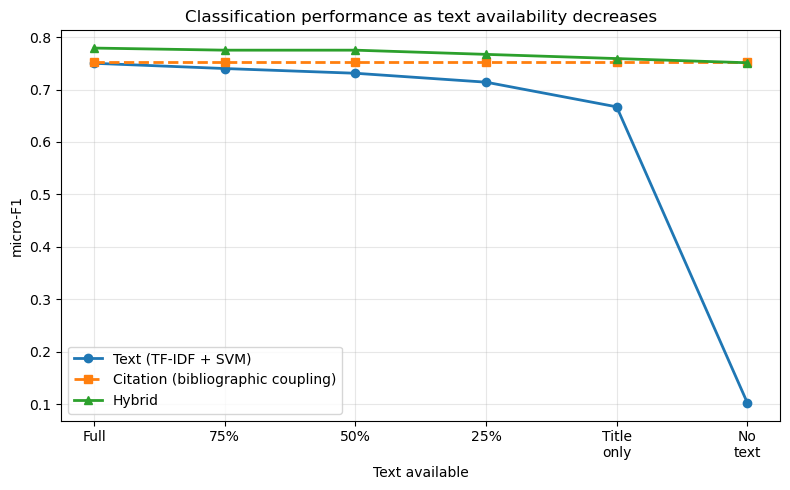

saved to /Users/kalai/Documents/Dissertation/Results/ablation_figure.png


In [8]:
import matplotlib.pyplot as plt

x = range(len(results))
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, results.text_micro, "o-", label="Text (TF-IDF + SVM)", linewidth=2)
ax.plot(x, results.cite_micro, "s--", label="Citation (bibliographic coupling)", linewidth=2)
ax.plot(x, results.hybrid_micro, "^-", label="Hybrid", linewidth=2)

ax.set_xticks(list(x))
ax.set_xticklabels(["Full", "75%", "50%", "25%", "Title\nonly", "No\ntext"])
ax.set_xlabel("Text available")
ax.set_ylabel("micro-F1")
ax.set_title("Classification performance as text availability decreases")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS / "ablation_figure.png", dpi=300)
plt.show()
print(f"saved to {RESULTS / 'ablation_figure.png'}")

In [9]:


SEEDS = [42, 7, 123, 2024, 555]
all_runs = []

for seed in SEEDS:
    print(f"seed {seed}...", end=" ", flush=True)

    
    dev_i, test_i = train_test_split(np.arange(len(df)), test_size=0.20,
                                     random_state=seed, shuffle=True)
    train_i, val_i = train_test_split(dev_i, test_size=0.25,
                                      random_state=seed, shuffle=True)

    
    bC, bs = None, -1
    for C in [0.1, 0.5, 1.0, 2.0]:
        s = text_scores(CONDITIONS["full"], train_i, val_i, C)
        m = evaluate(Y[val_i], to_labels(s, 0.0))[0]
        if m > bs:
            bs, bC = m, C

    
    bk, bct, bs = None, None, -1
    for k in [5, 10, 20, 30, 50]:
        s = citation_scores(train_i, val_i, k)
        for thr in [0.20, 0.25, 0.30, 0.35, 0.40]:
            m = evaluate(Y[val_i], to_labels(s, thr))[0]
            if m > bs:
                bs, bk, bct = m, k, thr

    
    cite_v = citation_scores(train_i, val_i, bk)
    settings = {}
    for cond, txt in CONDITIONS.items():
        tv = text_scores(txt, train_i, val_i, bC)
        bw, bt, bsc = 0.5, 0.0, -1
        for w in [0.0, 0.2, 0.35, 0.5, 0.65, 0.8, 1.0]:
            comb = (1 - w) * zscale(tv) + w * zscale(cite_v)
            for thr in [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]:
                m = evaluate(Y[val_i], to_labels(comb, thr))[0]
                if m > bsc:
                    bsc, bw, bt = m, w, thr
        settings[cond] = (bw, bt)

    
    fit_i = np.concatenate([train_i, val_i])
    cite_t = citation_scores(fit_i, test_i, bk)
    c_mi = evaluate(Y[test_i], to_labels(cite_t, bct))[0]

    for cond, txt in CONDITIONS.items():
        tt = text_scores(txt, fit_i, test_i, bC)
        t_mi = evaluate(Y[test_i], to_labels(tt, 0.0))[0]
        w, thr = settings[cond]
        comb = (1 - w) * zscale(tt) + w * zscale(cite_t)
        h_mi = evaluate(Y[test_i], to_labels(comb, thr))[0]

        all_runs.append({"seed": seed, "condition": cond,
                         "text": t_mi, "citation": c_mi, "hybrid": h_mi,
                         "w": w})
    print("done")

runs = pd.DataFrame(all_runs)
runs.to_csv(RESULTS / "ablation_all_seeds.csv", index=False)
print(f"\n{len(SEEDS)} seeds complete, saved to ablation_all_seeds.csv")

seed 42... done
seed 7... done
seed 123... done
seed 2024... done
seed 555... done

5 seeds complete, saved to ablation_all_seeds.csv


In [10]:
order = list(CONDITIONS.keys())

summary = (runs.groupby("condition")[["text", "citation", "hybrid"]]
              .agg(["mean", "std"]).reindex(order))

print("Averaged over 5 random splits (mean ± standard deviation)\n")
print(f"{'condition':<14}{'text':>16}{'citation':>16}{'hybrid':>16}")
for cond in order:
    r = summary.loc[cond]
    print(f"{cond:<14}"
          f"{r[('text','mean')]:>10.3f} ±{r[('text','std')]:.3f}"
          f"{r[('citation','mean')]:>10.3f} ±{r[('citation','std')]:.3f}"
          f"{r[('hybrid','mean')]:>10.3f} ±{r[('hybrid','std')]:.3f}")


print("\n\nWhich model wins, in each condition, for each seed:")
print(f"{'condition':<14}" + "".join(f"{s:>8}" for s in SEEDS))
for cond in order:
    marks = []
    for s in SEEDS:
        r = runs[(runs.seed == s) & (runs.condition == cond)].iloc[0]
        marks.append("text" if r.text > r.citation else "CITE")
    print(f"{cond:<14}" + "".join(f"{m:>8}" for m in marks))


print("\n\nOptimal citation weight per condition, by seed:")
print(f"{'condition':<14}" + "".join(f"{s:>8}" for s in SEEDS) + f"{'mean':>8}")
for cond in order:
    ws = [runs[(runs.seed == s) & (runs.condition == cond)].iloc[0].w for s in SEEDS]
    print(f"{cond:<14}" + "".join(f"{w:>8.2f}" for w in ws) + f"{np.mean(ws):>8.2f}")

Averaged over 5 random splits (mean ± standard deviation)

condition                 text        citation          hybrid
full               0.765 ±0.010     0.758 ±0.008     0.790 ±0.009
abstract_75        0.755 ±0.011     0.758 ±0.008     0.785 ±0.007
abstract_50        0.749 ±0.011     0.758 ±0.008     0.783 ±0.008
abstract_25        0.732 ±0.013     0.758 ±0.008     0.779 ±0.008
title_only         0.690 ±0.015     0.758 ±0.008     0.771 ±0.008
no_text            0.101 ±0.006     0.758 ±0.008     0.758 ±0.009


Which model wins, in each condition, for each seed:
condition           42       7     123    2024     555
full              CITE    CITE    text    text    text
abstract_75       CITE    CITE    text    text    CITE
abstract_50       CITE    CITE    CITE    text    CITE
abstract_25       CITE    CITE    CITE    CITE    CITE
title_only        CITE    CITE    CITE    CITE    CITE
no_text           CITE    CITE    CITE    CITE    CITE


Optimal citation weight per condition, by

In [11]:
def truncate_end(text, fraction):
    
    words = str(text).split()
    n = max(1, int(len(words) * fraction))
    return " ".join(words[-n:]) if words else ""

txt_end = (df.title + " " + df.abstract.apply(lambda t: truncate_end(t, .50))).values
s = text_scores(txt_end, fit_idx, test_idx, 2.0)
print("50% from END:  ", evaluate(Y[test_idx], to_labels(s, 0.0)))
print("50% from START: 0.731 (from ablation_results.csv)")

50% from END:   (0.733784669141734, 0.7288974116230349)
50% from START: 0.731 (from ablation_results.csv)


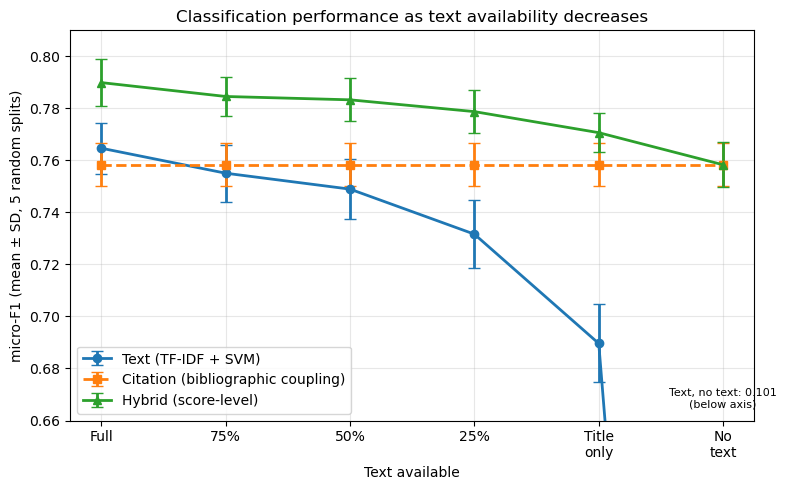

In [12]:

cond_labels = ["Full", "75%", "50%", "25%", "Title\nonly", "No\ntext"]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(8, 5))
for col, style, name in [("text", "o-", "Text (TF-IDF + SVM)"),
                         ("citation", "s--", "Citation (bibliographic coupling)"),
                         ("hybrid", "^-", "Hybrid (score-level)")]:
    ax.errorbar(x, summary[(col, "mean")].values, yerr=summary[(col, "std")].values,
                fmt=style, capsize=4, linewidth=2, label=name)

ax.set_ylim(0.66, 0.81)
ax.annotate("Text, no text: 0.101\n(below axis)", xy=(x[-1], 0.665),
            ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(cond_labels)
ax.set_xlabel("Text available")
ax.set_ylabel("micro-F1 (mean ± SD, 5 random splits)")
ax.set_title("Classification performance as text availability decreases")
ax.legend(loc="lower left"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "ablation_figure_5seeds.png", dpi=300)
plt.show()